[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/main/notebooks/f4_from_fisher_to_geometry.ipynb)

# From Fisher to geometry

* **Author**: simone.azeglio@gmail.com

* **Goal**: What does it mean that a code stretches stimulus space?

* **Needs**: a CPU, no data.

* **Time**: about 5 s.

* **Track**: Foundations, notebook 4. The line element $ds^2 = dx^\top J(x)\, dx$ and the bell-shaped and monotonic pair of the last section are those of Section 2 and Figure 1 of Azeglio, Laquitaine, Ferrari, Chalk (NeurIPS 2026, arXiv 2605.06304).

* **Next**: notebook f5 blurs the stimulus to build a tool that sees the code at every scale.

## 1. Setup

### 1.1. Install package

On Google Colab, install `multigeom`. Elsewhere this cell does nothing.

time: <1 sec

In [1]:
%%time

# on Google Colab install the package from PyPI, without its dependencies: Colab already
# has torch, numpy, scipy and matplotlib, and reinstalling torch is slow and can break
# the GPU runtime (nothing to do on your own machine)
import sys

if "google.colab" in sys.modules:
    %pip install -q --no-deps --pre multigeom

CPU times: user 4 μs, sys: 0 ns, total: 4 μs
Wall time: 7.15 μs


### 1.2. Imports

Import the packages, pick the device, compute in float64 and set the figure style. The device is `cuda` when there is a GPU and `cpu` otherwise, never `mps`, which has no float64.

time: <1 sec

In [2]:
%%time

import math

import matplotlib.pyplot as plt
import torch
from matplotlib.patches import ConnectionPatch, Ellipse

from multigeom.lowdim import (
    compute_fisher,
    cumulative_distance,
    distance,
    fisher_from_jacobian,
    mutual_information,
    to_bits,
)

# run on the GPU when there is one
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_default_dtype(torch.float64)
print("device:", device)

# figure style of the Foundations notebooks: 9 pt text or more, no top or right spines
plt.rcParams.update(
    {
        "font.size": 10,
        "axes.labelsize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "legend.frameon": False,
    }
)
TEAL, ROSE, VIOLET, INK, GREY = "#2A8C7E", "#B23A62", "#5b3fd1", "#1a1a1a", "#8a8a8a"

device: cpu
CPU times: user 706 ms, sys: 105 ms, total: 812 ms
Wall time: 991 ms


### 1.3. Parameters of the series

The stimulus $x$ lies on $[-3, 3]$ with the uniform prior $p(x) = 1/6$, sampled on 1,201 grid points. The response is $r = \text{tuning}(x) + \sigma z$, with $z$ a standard Gaussian and $\sigma = 0.1$. Three neurons share this noise: the bell-shaped neuron $f(x) = e^{-x^2/2}$, its monotonic twin $m(x)$, equal to $f(x)$ for $x < 0$ and to $2 - f(x)$ for $x \ge 0$, and the low-gain neuron $0.5\, m(x)$.

time: <1 sec

In [3]:
%%time

X_MIN, X_MAX = -3.0, 3.0  # stimulus range
N_X = 1201  # stimulus grid points (step 0.005)
SIGMA = 0.1  # standard deviation of the response noise

x = torch.linspace(X_MIN, X_MAX, N_X, device=device)
dx = (x[1] - x[0]).item()
prior = torch.ones_like(x) / (N_X * dx)  # uniform, sums to 1 on the grid

bell = torch.exp(-(x**2) / 2)
twin = torch.where(x < 0, bell, 2 - bell)
low_gain = 0.5 * twin
neurons = {"bell-shaped": bell, "monotonic twin": twin, "low-gain": low_gain}
colours = {"bell-shaped": VIOLET, "monotonic twin": INK, "low-gain": GREY}

CPU times: user 333 μs, sys: 216 μs, total: 549 μs
Wall time: 473 μs


## 2. A ruler on the stimulus axis

For a small step $dx$ from the stimulus $x$, the discriminability is $d' \approx \sqrt{J(x)}\, dx$, with $J(x) = f'(x)^2/\sigma^2$ the Fisher information. We take this as the length of the step, $ds = \sqrt{J(x)}\, dx$. The length of a longer interval is the sum of the lengths of its small steps, and the Fisher distance between two stimuli $a < b$ is

$$d_J(a, b) = \int_a^b \sqrt{J(x)}\; dx .$$

`cumulative_distance(x, J)` returns $d_J$ from the first grid point to every grid point, and `distance(x, J, a, b)` returns $d_J(a, b)$. Both use the trapezoid rule. The next cell measures three steps of the same size, 0.5, on the bell-shaped neuron.

time: <1 sec

In [4]:
%%time

J_bell = compute_fisher(x, bell, SIGMA)
STEPS = {"flank": (-1.25, -0.75), "peak": (-0.25, 0.25), "end": (-3.0, -2.5)}

step_lengths = {
    name: distance(x, J_bell, a, b).item() for name, (a, b) in STEPS.items()
}
for name, (a, b) in STEPS.items():
    print(f"{name:5s} step from {a:+.2f} to {b:+.2f}: length {step_lengths[name]:.2f}")
print("expected: flank 2.97, peak 0.62, end 0.33")
print(f"largest stretch sqrt(J): {J_bell.sqrt().max().item():.2f}   (expected 6.07)")
print(
    f"Fisher distance from -3 to 3: {distance(x, J_bell, -3, 3).item():.2f}"
    "   (expected 19.78)"
)

flank step from -1.25 to -0.75: length 2.97
peak  step from -0.25 to +0.25: length 0.62
end   step from -3.00 to -2.50: length 0.33
expected: flank 2.97, peak 0.62, end 0.33
largest stretch sqrt(J): 6.07   (expected 6.07)
Fisher distance from -3 to 3: 19.78   (expected 19.78)
CPU times: user 1.13 ms, sys: 234 μs, total: 1.36 ms
Wall time: 1.38 ms


Equal steps of the stimulus have different lengths. The stretch at $x$ is $\sqrt{J(x)}$, the number of $d'$ units per unit of stimulus. The figure redraws the stimulus axis so that equal lengths mean equal discriminability. Stimuli every 0.25 on the stimulus axis (top, under the curve of $J$) are joined to their positions $d_J(-3, x)$ on the Fisher-distance axis (bottom).

time: <1 sec

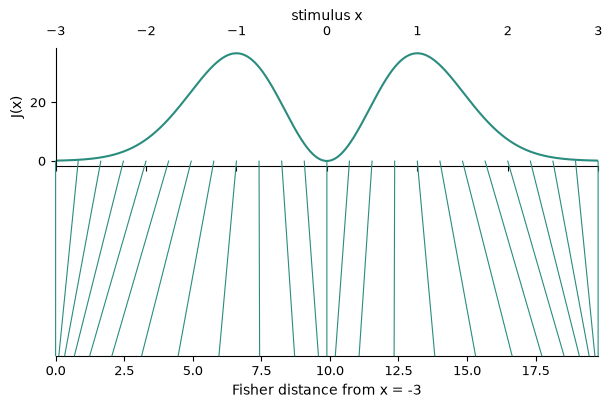

CPU times: user 64.2 ms, sys: 3.72 ms, total: 67.9 ms
Wall time: 70.8 ms


In [5]:
%%time

d_from_start = cumulative_distance(x, J_bell)
ticks = torch.arange(X_MIN, X_MAX + 0.01, 0.25, device=device)
tick_positions = distance(x, J_bell, X_MIN, ticks)

fig, (ax_j, ax_d) = plt.subplots(2, 1, figsize=(7, 4), gridspec_kw={"hspace": 0.6})
ax_j.plot(x.cpu(), J_bell.cpu(), color=TEAL)
ax_j.set_xlim(X_MIN, X_MAX)
ax_j.set_xlabel("stimulus x")
ax_j.xaxis.set_label_position("top")
ax_j.tick_params(labeltop=True, labelbottom=False)
ax_j.set_ylabel("J(x)")
ax_d.set_xlim(0, d_from_start[-1].item())
ax_d.set_yticks([])
ax_d.spines["left"].set_visible(False)
ax_d.set_xlabel("Fisher distance from x = -3")
for tick, position in zip(ticks.tolist(), tick_positions.tolist()):
    line = ConnectionPatch(
        (tick, 0),
        (position, 0),
        "data",
        "data",
        axesA=ax_j,
        axesB=ax_d,
        color=TEAL,
        lw=0.8,
    )
    fig.add_artist(line)
plt.show()

The flanks spread apart, and the peak and the two ends bunch together, because there a step of the stimulus changes the response little compared with the noise.

The Fisher distance does not depend on the units of the stimulus. Measure the stimulus as $y = 15x$. The Fisher information about $y$ is $J_y = J_x/15^2$, because each step $dy$ is 15 times larger than $dx$. The next cell checks that the distance from $x = -1$ to $x = +1$ is the same in both units.

time: <1 sec

In [6]:
%%time

UNIT_FACTOR = 15.0
y = UNIT_FACTOR * x
J_y = J_bell / UNIT_FACTOR**2

d_minus1_to_1 = distance(x, J_bell, -1.0, 1.0).item()
d_in_new_units = distance(y, J_y, -UNIT_FACTOR, UNIT_FACTOR).item()
print(f"stimulus units:      d_J(-1, 1) = {d_minus1_to_1:.2f}   (expected 7.87)")
print(f"units 15 times smaller: d_J(-15, 15) = {d_in_new_units:.2f}")

stimulus units:      d_J(-1, 1) = 7.87   (expected 7.87)
units 15 times smaller: d_J(-15, 15) = 7.87
CPU times: user 551 μs, sys: 97 μs, total: 648 μs
Wall time: 576 μs


## 3. Two stimulus dimensions

A stimulus with two components, $x = (x_1, x_2)$, makes the Fisher information a $2 \times 2$ matrix. For neurons with independent Gaussian noise of standard deviation $\sigma$,

$$J(x) = \frac{A(x)^\top A(x)}{\sigma^2}, \qquad A_{ij} = \frac{\partial f_i}{\partial x_j},$$

where $A$ is the Jacobian of the tuning curves. The squared length of a small step is $ds^2 = dx^\top J(x)\, dx$, the squared $d'$ of the step for the whole population. The eigenvectors of $J$ are the directions of steps that the code tells apart best and worst, and each eigenvalue is the squared $d'$ per unit step along its eigenvector.

Our example has two neurons with sigmoid tuning curves $f_i(x) = 1/(1 + e^{-w_i^\top x})$. The preferred directions are $w_1 = k\,(1, 0)$ and $w_2 = k\,(\cos\theta, \sin\theta)$, with $k = 1.2$ and $\theta = 60°$. Since $\nabla f_i = f_i (1 - f_i)\, w_i$, the Jacobian has a closed form. The next cell builds it, checks it against automatic differentiation at one stimulus, and passes it to `fisher_from_jacobian`.

time: <1 sec

In [7]:
%%time

GAIN = 1.2  # k
ANGLE = 60.0  # theta, in degrees


def preferred_directions(angle=ANGLE):
    """w_1 and w_2 as the rows of a 2 x 2 matrix."""
    theta = math.radians(angle)
    return GAIN * torch.tensor([[1.0, 0.0], [math.cos(theta), math.sin(theta)]])


def sigmoid_jacobian(points, w):
    """Jacobian A [..., 2 neurons, 2 components] of the two sigmoid neurons."""
    rates = torch.sigmoid(points @ w.T)
    return (rates * (1 - rates))[..., None] * w


W = preferred_directions()
probe = torch.tensor([0.7, -0.4])
autograd = torch.autograd.functional.jacobian(lambda p: torch.sigmoid(W @ p), probe)
gap = (sigmoid_jacobian(probe, W) - autograd).abs().max()
print(f"closed form against autograd: {gap:.1e}")

J_origin = fisher_from_jacobian(sigmoid_jacobian(torch.zeros(2), W), SIGMA)
eigenvalues, eigenvectors = torch.linalg.eigh(J_origin)  # ascending
leading_angle = math.degrees(math.atan2(eigenvectors[1, 1], eigenvectors[0, 1])) % 180
print(
    f"eigenvalues at the origin: {eigenvalues[1]:.1f} and {eigenvalues[0]:.1f}"
    "   (expected 13.5 and 4.5)"
)
print(f"leading eigenvector at {leading_angle:.1f} degrees   (expected 30)")

closed form against autograd: 0.0e+00
eigenvalues at the origin: 13.5 and 4.5   (expected 13.5 and 4.5)
leading eigenvector at 30.0 degrees   (expected 30)
CPU times: user 4.02 ms, sys: 3.81 ms, total: 7.83 ms
Wall time: 12.2 ms


At the origin both neurons respond at half their maximum, and each adds $0.25^2 k^2/\sigma^2 = 9$ along its preferred direction. The leading eigenvector points halfway between the two preferred directions.

The next cell compares, for a step of length 0.1 along each eigenvector, the exact $d'$ with the prediction $\sqrt{dx^\top J\, dx}$. The exact $d'$ is the length of the change of the two mean responses, divided by $\sigma$.

time: <1 sec

In [8]:
%%time

STEP = 0.1
for name, k in (("best", 1), ("worst", 0)):
    step = STEP * eigenvectors[:, k]
    exact = (torch.sigmoid(W @ step) - torch.sigmoid(torch.zeros(2))).norm() / SIGMA
    predicted = (step @ J_origin @ step).sqrt()
    print(f"{name:5s} direction: exact d' {exact:.3f}, predicted {predicted:.3f}")
print("expected: 0.37 along the best direction, 0.21 at right angles")

best  direction: exact d' 0.367, predicted 0.367
worst direction: exact d' 0.212, predicted 0.212
expected: 0.37 along the best direction, 0.21 at right angles
CPU times: user 678 μs, sys: 285 μs, total: 963 μs
Wall time: 890 μs


We draw $J$ as an ellipse at each stimulus of a 9 by 9 grid. The axes of an ellipse follow the eigenvectors, with half-lengths proportional to the square roots of the eigenvalues, one scale for the whole field. A bigger ellipse means a more sensitive code, and the long axis is the direction the code tells apart best. The grey lines are lines of equal mean response of each neuron.

time: <1 sec

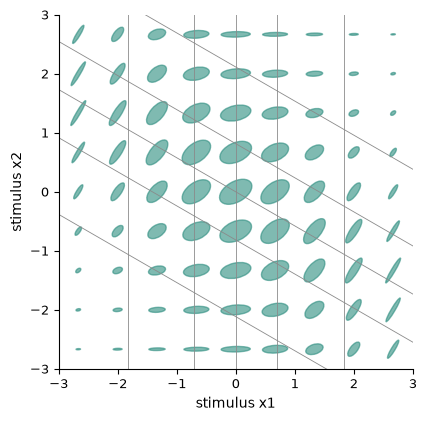

CPU times: user 77.4 ms, sys: 1.53 ms, total: 78.9 ms
Wall time: 79 ms


In [9]:
%%time

N_CELLS = 9
centres = X_MIN + (torch.arange(N_CELLS) + 0.5) * (X_MAX - X_MIN) / N_CELLS
points = torch.cartesian_prod(centres, centres)  # [81, 2]
field = fisher_from_jacobian(sigmoid_jacobian(points, W), SIGMA)  # [81, 2, 2]
values, vectors = torch.linalg.eigh(field)
scale = 0.45 * (X_MAX - X_MIN) / N_CELLS / values[:, 1].max().sqrt()

fig, ax = plt.subplots(figsize=(4.6, 4.6))
level_line = torch.linspace(X_MIN - 2, X_MAX + 2, 2)
for w in W:
    normal = torch.stack([-w[1], w[0]]) / w.norm()
    for level in (0.1, 0.3, 0.5, 0.7, 0.9):  # f_i = level along w_i^T x = logit(level)
        foot = math.log(level / (1 - level)) * w / w.norm() ** 2
        ax.plot(*(foot[:, None] + normal[:, None] * level_line), color=GREY, lw=0.6)
for p, lam, vec in zip(points, values, vectors):
    angle = math.degrees(math.atan2(vec[1, 1], vec[0, 1]))
    width, height = 2 * scale * lam.flip(0).clamp_min(0).sqrt()
    ax.add_patch(Ellipse(p, width, height, angle=angle, color=TEAL, alpha=0.6))
ax.set(xlim=(X_MIN, X_MAX), ylim=(X_MIN, X_MAX), aspect="equal")
ax.set_xlabel("stimulus x1")
ax.set_ylabel("stimulus x2")
plt.show()

The ellipses are largest near the origin, where both neurons respond near half their maximum. They shrink where both neurons respond near zero or near their maximum, and they become thin where only one neuron changes its response.

## 4. Same Fisher, different information

The three neurons of the series show the cost of a local metric. The bell-shaped neuron and its twin have slopes of the same size at every stimulus, so their Fisher information is the same function of $x$. The low-gain neuron has half the slope of the twin everywhere. The next cell computes, for each neuron, the Fisher distance from $x = -3$ to every stimulus and the mutual information under the uniform prior.

time: <1 sec

In [10]:
%%time

fisher = {name: compute_fisher(x, tuning, SIGMA) for name, tuning in neurons.items()}
fisher_distance = {name: distance(x, J, -3.0, 3.0).item() for name, J in fisher.items()}
mi_bits = {
    name: to_bits(mutual_information(x, tuning, prior, SIGMA)).item()
    for name, tuning in neurons.items()
}
for name in neurons:
    print(
        f"{name:15s} d_J(-3, 3) = {fisher_distance[name]:.2f}, "
        f"I(R; X) = {mi_bits[name]:.3f} bits"
    )
print("expected d_J: 19.78, 19.78, 9.89 | I: 1.603, 2.419, 1.662 bits")

bell-shaped     d_J(-3, 3) = 19.78, I(R; X) = 1.603 bits
monotonic twin  d_J(-3, 3) = 19.78, I(R; X) = 2.419 bits
low-gain        d_J(-3, 3) = 9.89, I(R; X) = 1.662 bits
expected d_J: 19.78, 19.78, 9.89 | I: 1.603, 2.419, 1.662 bits
CPU times: user 18.1 ms, sys: 11.8 ms, total: 29.9 ms
Wall time: 23.2 ms


The figure shows the three tuning curves, their mutual information and their Fisher distances from $x = -3$. The curves of the bell-shaped neuron and of its twin in the right panel lie on top of each other.

time: <1 sec

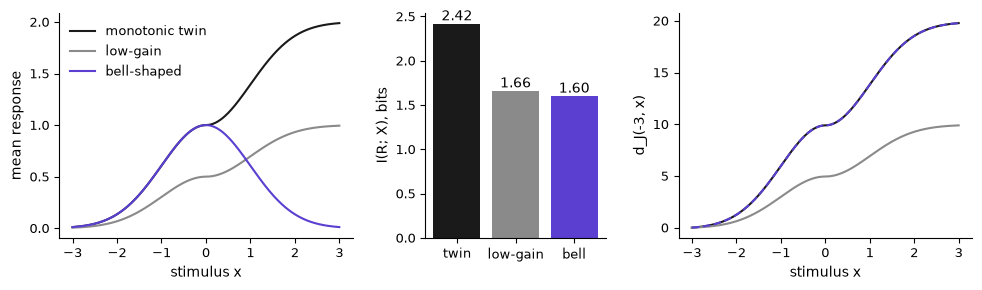

CPU times: user 89.8 ms, sys: 5.02 ms, total: 94.9 ms
Wall time: 95 ms


In [11]:
%%time

order = ["monotonic twin", "low-gain", "bell-shaped"]
fig, (ax_f, ax_i, ax_d) = plt.subplots(
    1, 3, figsize=(10, 3), gridspec_kw={"width_ratios": [1.3, 0.8, 1.3]}
)
for name in order:
    ax_f.plot(x.cpu(), neurons[name].cpu(), color=colours[name], label=name)
    style = "--" if name == "bell-shaped" else "-"
    d = cumulative_distance(x, fisher[name]).cpu()
    ax_d.plot(x.cpu(), d, style, color=colours[name])
bars = ax_i.bar(
    range(3), [mi_bits[n] for n in order], color=[colours[n] for n in order]
)
ax_i.bar_label(bars, fmt="%.2f")
ax_i.set_xticks(range(3), ["twin", "low-gain", "bell"])
ax_f.legend(loc="upper left")
ax_f.set(xlabel="stimulus x", ylabel="mean response")
ax_i.set_ylabel("I(R; X), bits")
ax_d.set(xlabel="stimulus x", ylabel="d_J(-3, x)")
plt.tight_layout()
plt.show()

The bell-shaped neuron stretches the axis as much as its twin and carries the least information of the three. The next cell shows why, with the stimuli $x = -1$ and $x = +1$. The Fisher distance adds the rise of the tuning curve from $-1$ to $0$ and its fall from $0$ to $1$. The $d'$ of the two end stimuli compares only their mean responses.

time: <1 sec

In [12]:
%%time

for name in ("bell-shaped", "monotonic twin"):
    tuning = neurons[name]
    i_minus, i_plus = torch.argmin((x + 1).abs()), torch.argmin((x - 1).abs())
    d_prime_ends = (tuning[i_plus] - tuning[i_minus]).abs().item() / SIGMA
    d_J_ends = distance(x, fisher[name], -1.0, 1.0).item()
    print(
        f"{name:15s} d_J(-1, 1) = {d_J_ends:.2f}, d' of -1 and 1 = {d_prime_ends:.2f}"
    )
print("expected: bell 7.87 and 0 | twin 7.87 and 7.87")

bell-shaped     d_J(-1, 1) = 7.87, d' of -1 and 1 = 0.00
monotonic twin  d_J(-1, 1) = 7.87, d' of -1 and 1 = 7.87
expected: bell 7.87 and 0 | twin 7.87 and 7.87
CPU times: user 834 μs, sys: 211 μs, total: 1.05 ms
Wall time: 1.08 ms


For the twin, which only rises, the Fisher distance equals the $d'$ of the end stimuli. For the bell-shaped neuron the two stimuli give the same response distribution, so $d' = 0$, while the Fisher distance is still 7.87. Stimuli far apart that give the same responses are a global ambiguity, and a metric that compares each stimulus only with its immediate neighbours cannot see it.

## 5. Try it

* Set the angle $\theta$ to $0°$, so that both sigmoid neurons prefer the same direction. Look at the eigenvalues at the origin and at the shape of the ellipses.
* Move the probe of Section 3 to $(2, 2)$, where both neurons respond near their maximum. The eigenvalues fall to 0.89 and 0.12.
* Double the noise to $\sigma = 0.2$. Every Fisher distance is halved. Compare with the mutual information, which falls by a different amount for each neuron.

The next cell carries out the first change.

time: <1 sec

In [13]:
%%time

W_parallel = preferred_directions(angle=0.0)
J_parallel = fisher_from_jacobian(sigmoid_jacobian(torch.zeros(2), W_parallel), SIGMA)
eigenvalues_parallel = torch.linalg.eigvalsh(J_parallel)
print(
    f"theta = 0: eigenvalues at the origin {eigenvalues_parallel[1]:.1f} and "
    f"{eigenvalues_parallel[0]:.1f}   (expected 18 and 0)"
)

theta = 0: eigenvalues at the origin 18.0 and 0.0   (expected 18 and 0)
CPU times: user 394 μs, sys: 118 μs, total: 512 μs
Wall time: 444 μs


With $\theta = 0$ the two neurons are blind along the same lines, so one eigenvalue is zero and every ellipse collapses to a segment. Two distinct stimuli on such a line are then at Fisher distance zero.

**Next**: [notebook f5](f5_noise_as_a_ruler.ipynb) blurs the stimulus with Gaussian noise of growing width, the tool that the multi-scale Fisher information is built on.